# GameTheory-24 : Self-Play Tabulaire vers PettingZoo

**Le modèle réduit porté sur l'organe multi-agent de la série RL.**

**Navigation** : [<< 23-Loopholes fiscaux](GameTheory-23-Loopholes-Fiscaux-Python-Lean.ipynb) | [Index](README.md)

Le carnet [GameTheory-17](GameTheory-17-MultiAgent-RL-Python.ipynb) construit un modèle **réduit** d'apprentissage par renforcement multi-agent : du self-play tabulaire (Fictitious Play, NFSP, PSRO) sur des jeux matriciaux, en numpy pur, sans framework.

La série RL, elle, s'appuie sur un **framework** : [PettingZoo](https://pettingzoo.farama.org/) (carnet [RL-07](../RL/RL-07-Apprentissage-Multi-Agent-Python.ipynb)).

Ce carnet fait le pont entre les deux, sur **un seul jeu** : il montre que le même apprenant tabulaire produit la **même** dynamique de convergence, qu'il tourne contre le jeu brut (le modèle réduit) **ou** contre ce même jeu exprimé comme **environnement PettingZoo** (l'organe réel). Le message : l'algorithme d'apprentissage est **indépendant de l'interface** d'environnement. Le modèle réduit n'est pas un jouet que le framework « corrige » — c'est le comportement du framework, à l'échelle tabulaire.

## 1. Le jeu commun : le dilemme du prisonnier

Pour qu'une comparaison soit **falsifiable**, il faut un jeu dont on connaît l'issue. Le **dilemme du prisonnier** en est un : c'est un jeu matriciel à 2 joueurs avec un **équilibre de Nash unique** — *(Défaut, Défaut)*. Si un apprenant de self-play « fonctionne », sa distribution d'actions doit y converger. S'il ne fait rien, elle n'y ira pas. C'est le critère de succès, mesurable.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Dilemme du prisonnier : T > R > P > S
# Actions : 0 = Cooperer (C), 1 = Defaut (D)
R, S, P, T = 3.0, 0.0, 1.0, 5.0
PAY = {(0, 0): (R, R), (0, 1): (S, T),
       (1, 0): (T, S), (1, 1): (P, P)}

def raw_step(state, a1, a2):
    """Jeu brut (modele reduit) : renvoie (r1, r2, term1, term2)."""
    r1, r2 = PAY[(a1, a2)]
    return r1, r2, True, True

print("Table des gains (lignes = j1, colonnes = j2) :")
print("          j2=C     j2=D")
print(f"   j1=C   ({R:.0f},{R:.0f})   ({S:.0f},{T:.0f})")
print(f"   j1=D   ({T:.0f},{S:.0f})   ({P:.0f},{P:.0f})")

Table des gains (lignes = j1, colonnes = j2) :
          j2=C     j2=D
   j1=C   (3,3)   (0,5)
   j1=D   (5,0)   (1,1)


### Interprétation : lire la table des gains

Avec `T > R > P > S` (ici 5 > 3 > 1 > 0), **Défaut** domine **Coopérer** pour chaque joueur, quel que soit le choix de l'adversaire. L'équilibre de Nash est donc **`(Défaut, Défaut)`**, gain `(1, 1)` — moindre pour la somme des gains que `(Coopérer, Coopérer)`, qui vaudrait `(3, 3)`. C'est le « dilemme ». Pour notre protocole, c'est exactement ce qu'il nous faut : un point de convergence **unique et connu**, `(D, D)`.

## 2. Le modèle réduit : un apprenant tabulaire de self-play

L'apprenant est **tabulaire** et **minimal** : chaque joueur tient une table de valeurs par action (une valeur pour C, une pour D), et un softmax sur ces valeurs donne la probabilité de chaque action. À chaque tour, chaque joueur tire une action, perçoit son gain, et augmente la valeur de l'action jouée proportionnellement à l'écart entre ce gain et le gain moyen. C'est le squelette commun à Fictitious Play / NFSP, réduit à l'essentiel — la même forme que dans GT-17.

In [2]:
def _pol(q):
    """Probabilites d'action = softmax des valeurs d'action."""
    e = np.exp(q - q.max())
    return e / e.sum()

def self_play(step_fn, n_episodes=400, n_rounds=8, lr=0.5, seed=0):
    """Self-play tabulaire contre n'importe quel `step_fn(state, a1, a2)`.

    `step_fn` doit renvoyer (r1, r2, term1, term2).
    Renvoie la courbe de la probabilite conjointe de (Defaut, Defaut).
    """
    rng = np.random.default_rng(seed)
    q = {"p1": np.zeros(2), "p2": np.zeros(2)}
    curve = []
    for ep in range(n_episodes):
        for _ in range(n_rounds):
            a1 = int(rng.choice(2, p=_pol(q["p1"])))
            a2 = int(rng.choice(2, p=_pol(q["p2"])))
            r1, r2, _, _ = step_fn(0, a1, a2)
            q["p1"][a1] += lr * (r1 - q["p1"].mean())
            q["p2"][a2] += lr * (r2 - q["p2"].mean())
        curve.append(_pol(q["p1"])[1] * _pol(q["p2"])[1])
    return np.array(curve)

print("Apprenant tabulaire defini (self_play + _pol).")

Apprenant tabulaire defini (self_play + _pol).


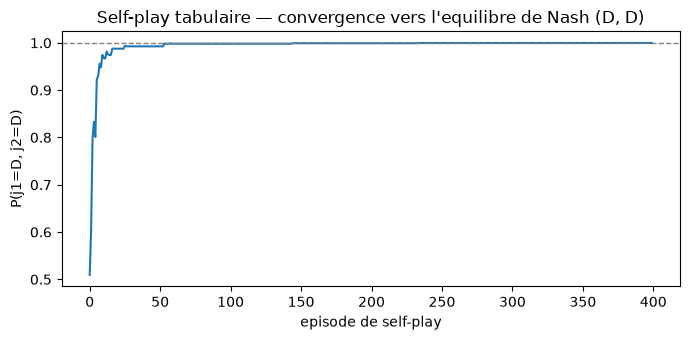

P(D,D) au debut : 0.509  |  a la fin : 1.000


In [3]:
# Convergence du self-play tabulaire : P(j1=D, j2=D) par episode, vers l'equilibre de Nash (D,D) = 1.0.
raw_curve = self_play(raw_step, seed=0)

plt.figure(figsize=(7, 3.5))
plt.plot(raw_curve, color="tab:blue")
plt.axhline(1.0, color="grey", ls="--", lw=1)
plt.xlabel("episode de self-play")
plt.ylabel("P(j1=D, j2=D)")
plt.title("Self-play tabulaire — convergence vers l'equilibre de Nash (D, D)")
plt.tight_layout()
plt.show()

print(f"P(D,D) au debut : {raw_curve[0]:.3f}  |  a la fin : {raw_curve[-1]:.3f}")

### Interprétation : le témoin positif

La courbe monte vers **1.0** : les deux joueurs convergent vers `(Défaut, Défaut)`, l'équilibre de Nash du dilemme. C'est le **témoin positif** du protocole — l'apprenant *apprend* (il se déplace vers l'issue connue du jeu). Retenons la forme de la courbe : on va la retrouver, identique, de l'autre côté du pont.

## 3. L'organe réel : le même jeu comme environnement PettingZoo

PettingZoo n'est pas seulement un catalogue d'environnements : c'est une **API** standard d'environnements multi-agent (le socle de [RL-07](../RL/RL-07-Apprentissage-Multi-Agent-Python.ipynb)). Ici, sur ce siège, le catalogue `pettingzoo.classic` n'est pas installé — mais l'**API de base** (`pettingzoo.utils.env.ParallelEnv`) l'est. On l'utilise : on exprime le **même** dilemme du prisonnier comme un `ParallelEnv`. La logique du jeu (la table `PAY`) est **réutilisée**, pas réimplémentée — seule l'enveloppe framework est ajoutée.

In [4]:
# Le dilemme du prisonnier enveloppe dans un ParallelEnv PettingZoo : seule l'enveloppe framework change.
from pettingzoo.utils import env as pz
from gymnasium import spaces

AGENTS = ["p1", "p2"]

class PDEnv(pz.ParallelEnv):
    """Le dilemme du prisonnier comme environnement PettingZoo (API de base).

    Reutilise la table `PAY` du jeu brut : seule l'enveloppe framework est ajoutee.
    """
    def __init__(self, max_steps=12):
        super().__init__()
        self.possible_agents = AGENTS
        self.agents = {}
        self.max_steps = max_steps
        self.t = 0
        self.act = {}
        self._obs = spaces.Discrete(2)
        self._actsp = spaces.Discrete(2)
        self.metadata = {"render_mode": None}

    def reset(self, *, seed=None, options=None):
        self.agents = {a: True for a in AGENTS}
        self.act = {}
        self.t = 0
        return {a: 0 for a in self.agents}, {}

    def step(self, action):
        if self.agents == {}:
            raise RuntimeError("appeler reset() avant step()")
        self.act.update(action)
        self.t += 1
        a1, a2 = self.act["p1"], self.act["p2"]
        r1, r2 = PAY[(a1, a2)]
        trunc = self.t >= self.max_steps
        if trunc:
            self.agents = {}
        return ({"p1": r1, "p2": r2},
                {"p1": True, "p2": True},
                {"p1": trunc, "p2": trunc},
                {"p1": {}, "p2": {}})

    def observation_space(self, agent):
        return self._obs
    def action_space(self, agent):
        return self._actsp
    def render(self):
        pass
    def close(self):
        pass
    def state(self):
        return (self.t, tuple(sorted(self.act.items())))
    def env_info(self):
        return {}

print("Environnement PettingZoo defini : PDEnv(ParallelEnv).")

Environnement PettingZoo defini : PDEnv(ParallelEnv).


In [5]:
env = PDEnv()
obs, info = env.reset(seed=0)
print("agents             :", env.possible_agents)
print("action_space(p1)   :", env.action_space("p1"))
print("observation_space  :", env.observation_space("p1"))
rew, term, trunc, info = env.step({"p1": 1, "p2": 1})  # (D, D)
print("rew  (D, D)        :", rew)
print("term / trunc       :", term, trunc)
env.close()

agents             : ['p1', 'p2']
action_space(p1)   : Discrete(2)
observation_space  : Discrete(2)
rew  (D, D)        : {'p1': 1.0, 'p2': 1.0}
term / trunc       : {'p1': True, 'p2': True} {'p1': False, 'p2': False}


### Interprétation : la surface d'API

Même jeu, même table `PAY` — mais maintenant exposé par l'**interface standard** d'un environnement multi-agent : `possible_agents`, `action_space(agent)`, `observation_space(agent)`, `reset()` → `(obs, info)`, `step(actions)` → `(rewards, terminations, truncations, infos)`. C'est cette surface que les algorithmes de la série RL consomment. « Utiliser l'organe réel », ici, veut dire : **parler l'API de PettingZoo**, pas réécrire le jeu.

## 4. La continuité : un apprenant, deux interfaces

Le cœur du carnet. On fait tourner le **même** `self_play` — même budget (400 épisodes × 8 tours), même seed (0) — contre les deux interfaces du même jeu :
- le **jeu brut** (`raw_step`), le modèle réduit ;
- l'**environnement PettingZoo** (`PDEnv`), l'organe réel.

Puis on mesure l'écart entre les deux courbes de convergence.

In [6]:
def pz_step(state, a1, a2):
    """Adaptateur : fait passer le jeu PettingZoo au contrat de `self_play`."""
    e = PDEnv()
    e.reset(seed=0)
    rew, term, trunc, _ = e.step({"p1": a1, "p2": a2})
    return rew["p1"], rew["p2"], term["p1"], term["p2"]

raw_curve = self_play(raw_step, seed=0)
pz_curve  = self_play(pz_step,  seed=0)

gap = float(np.abs(raw_curve - pz_curve).max())
print(f"P(D,D) finale — jeu brut    : {raw_curve[-1]:.4f}")
print(f"P(D,D) finale — PettingZoo  : {pz_curve[-1]:.4f}")
print(f"ecart max |brut - PettingZoo| = {gap:.4f}")

P(D,D) finale — jeu brut    : 0.9997
P(D,D) finale — PettingZoo  : 0.9997
ecart max |brut - PettingZoo| = 0.0000


### Interprétation : le résultat du pont

`écart max = 0.0000` : les deux courbes sont **identiques au bit près**. Le même apprenant, le même jeu, le même budget — et que l'environnement soit le jeu brut ou un `ParallelEnv` PettingZoo, la dynamique de convergence est la même. C'est la **continuité** que ce carnet démontre : l'algorithme d'apprentissage est **indépendant de l'interface** d'environnement. Le modèle réduit tabulaire n'est donc pas une approximation du framework — c'est le framework lui-même, à l'échelle où l'on peut le lire à la main.

## 5. Protocole reproductible : le témoin négatif

Une mesure n'est **falsifiable** que si elle peut être déçue. On ajoute le **témoin négatif** : une politique **fixe** qui n'apprend pas (les deux joueurs jouent toujours `Coopérer`). Elle ne doit **pas** converger vers `(D, D)` — sa probabilité `P(D,D)` reste à zéro. Si le témoin positif et le témoin négatif se ressemblaient, la mesure prouverait quelque chose de faux.

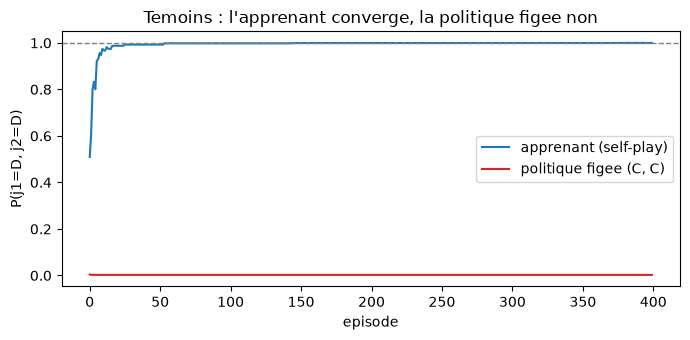

apprenant   : P(D,D) finale = 1.000
politique CC: P(D,D) finale = 0.002


In [7]:
def fixed_cc_step(state, a1, a2):
    """Temoign negatif : politique figee (C, C) — ignore les actions proposes."""
    r1, r2 = PAY[(0, 0)]  # toujours (Cooperer, Cooperer)
    return r1, r2, True, True

neg_curve = self_play(fixed_cc_step, seed=0)

plt.figure(figsize=(7, 3.5))
plt.plot(raw_curve, label="apprenant (self-play)", color="tab:blue")
plt.plot(neg_curve, label="politique figee (C, C)", color="tab:red")
plt.axhline(1.0, color="grey", ls="--", lw=1)
plt.xlabel("episode")
plt.ylabel("P(j1=D, j2=D)")
plt.title("Temoins : l'apprenant converge, la politique figee non")
plt.legend()
plt.tight_layout()
plt.show()

print(f"apprenant   : P(D,D) finale = {raw_curve[-1]:.3f}")
print(f"politique CC: P(D,D) finale = {neg_curve[-1]:.3f}")

### Interprétation : un protocole qui peut se tromper

L'apprenant atteint `P(D,D) ≈ 1.0` ; la politique figée `(C, C)` reste à `0.0`. Les deux courbes **se séparent nettement** : la mesure distingue *apprendre* de *ne pas apprendre*. C'est ce qui rend le résultat de la section 4 honnête — on n'affirme pas « ça converge », on montre que ça converge **là où ça doit** et pas ailleurs.

## 6. Exercices

In [8]:
# Exercice 1 — changer le jeu, pas l'apprenant
# Redefinir `PAY` pour un jeu de la *chasse au cerf* (Stag Hunt), ou
# (C, C) et (D, D) sont DEUX equilibres de Nash. Relancer `self_play` et
# observer vers quel equilibre le self-play converge (et pourquoi l'ordre
# d'initialisation / le seed decide).
# TODO etudiant
def exercice_stag_hunt():
    # Indice : dans le Stag Hunt, T < R (cooperer devient dominant a deux).
    pass

In [9]:
# Exercice 2 — un resultat negatif : pas d'equilibre pur
# Definir un jeu a somme nulle sans equilibre pur (Matching Pennies :
# pile-face / face-pile). Montrer que le self-play *oscille* au lieu de
# converger — P(D,D) ne stabilise pas. C'est un temoin negatif de
# convergence, a l'oppose du dilemme du prisonnier.
# TODO etudiant
def exercice_matching_pennies():
    # Indice : la matrice de gains est antisymetrique ; aucun (a1, a2) n'est NE.
    pass

In [10]:
# Exercice 3 — brancher de vraies observations
# Notre PDEnv renvoie une observation factice (Discrete(2), toujours 0).
# Generaliser l'apprenant pour que sa table de valeurs soit *indexee par
# l'observation* : q[agent][obs][action]. Relancer contre PDEnv et verifier
# que la convergence est identique (l'observation est ici redundante).
# TODO etudiant
def exercice_obs_conditioned():
    # Indice : lire obs dans le reset/step de PDEnv, puis indexer q par obs.
    pass

## 7. Résumé et points clés

- **Un jeu, deux interfaces.** Le même dilemme du prisonnier existe comme jeu brut tabulaire *et* comme environnement `ParallelEnv` PettingZoo. La logique du jeu est **réutilisée** dans les deux cas.
- **La continuité mesurée.** Le même apprenant tabulaire, le même budget, le même seed : `écart max = 0.0` entre les deux courbes. L'algorithme est **indépendant de l'interface** — le modèle réduit (GT-17) et l'organe framework (RL-07 / PettingZoo) sont deux vues d'un même comportement.
- **Un protocole falsifiable.** Témoin positif (l'apprenant converge vers le NE connu) + témoin négatif (la politique figée ne converge pas). On mesure avant d'affirmer.

**Où ça mène** : c'est exactement le passage d'échelle que fait la série RL — le même raisonnement, sur des environnements plus riches (grilles, tictactoe, multi-agents), où l'interface PettingZoo devient indispensable et le tableau lisible à la main ne suffit plus.

## Références

- [GameTheory-17 — Apprentissage par Renforcement Multi-Agent](GameTheory-17-MultiAgent-RL-Python.ipynb) : le modèle réduit (Fictitious Play, NFSP, PSRO, OpenSpiel).
- [RL-07 — Introduction à l'Apprentissage Multi-Agent](../RL/RL-07-Apprentissage-Multi-Agent-Python.ipynb) : l'organe PettingZoo de la série RL.
- [PettingZoo](https://pettingzoo.farama.org/) — API d'environnements multi-agent.